# A glucose–insulin digital twin, end to end

This notebook walks through the whole project in order: how the data is made, what the model
is and why, how we evaluate without cheating, and what came out. It loads the trained models
from `results/checkpoints/`, so nothing here retrains for long. The heavy runs live in
`scripts/0*.py`.

If you come from signal processing like I do, most of the biology turns out to be familiar
objects: low-pass filters, a bilinear system, a noisy sensor, and an unknown plant we want to
identify per patient.

**Everything here is on simulated patients. Nothing in this notebook is medical advice.**

Contents:
1. The problem
2. Making the data (UVA/Padova simulator)
3. The forecasting task and how we avoid leakage
4. Baselines: persistence and ARX
5. The mechanistic model (theory)
6. The hybrid: a neural network inside the ODE
7. Pure neural models
8. Personalisation with uncertainty (Laplace)
9. A failure that matters: the insulin sign flip
10. The agent on top
11. Results and what they do and don't say

In [1]:
import os, json, time
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import torch
import matplotlib.pyplot as plt

from biotwin.data.dataset import (Cohort, standard_sets, subset, LH, H, STEPS_PER_DAY, ADAPT_DAYS)
from biotwin.evaluate import point_metrics
from biotwin.train import predict

torch.set_num_threads(4)
plt.rcParams.update({"figure.figsize": (10, 3.2), "axes.grid": True, "grid.alpha": 0.3})
CKPT = Path("results/checkpoints")
print("torch", torch.__version__)

torch 2.11.0


## 1. The problem

A person with type-1 diabetes doesn't make insulin. They wear a **CGM** (continuous glucose
monitor) that reports glucose every 5 minutes, and they inject insulin: a slow constant
**basal** rate plus **boluses** at meals. Carbs push glucose up and insulin pulls it down, both
with delays.

In SP terms:

| Biology | What it is for us |
|---|---|
| Glucose (mg/dL) | the output $y[n]$, sampled every 5 min |
| CGM sensor | a noisy, slightly lagged measurement of it |
| Insulin, carbs | two known inputs $u[n]$, $r[n]$ |
| Absorption from skin / gut | low-pass filters (a couple of first-order stages) |
| "Insulin sensitivity" | a gain that differs a lot between people |
| Normal range | roughly 70–180 mg/dL; below 70 is hypoglycaemia (dangerous fast) |

A **digital twin** here means a model of *one* patient that can answer "what if": what happens
in the next hour if they eat 60 g now, or take 2 U of insulin. That is a forecasting problem
conditioned on *planned* future inputs.

There's a longer primer in `docs/biology_primer.md`.

## 2. Making the data

Real CGM datasets (OhioT1DM and others) need a data-use agreement, so we use the open-source
**UVA/Padova simulator** through [`simglucose`](https://github.com/jxx123/simglucose) (MIT
license). It ships 30 virtual patients (10 children, 10 adolescents, 10 adults), each with its
own physiology, and a realistic CGM noise model.

Two things about the simulator matter for the rest of the notebook:

- The simulator is a **13-state** model. The model we fit later is a **7-state** simplification
  of it. If they were the same model the mechanistic approach would win trivially, so this
  mismatch is on purpose.
- We know the **true** blood glucose as well as the noisy CGM. The true value is never a model
  input; we only use it to measure the sensor noise floor.

The patients' self-management is deliberately imperfect: carb counts are off by about ±20 %,
10 % of meals get no bolus, boluses are sometimes early or late, and there are rescue carbs
when glucose drops under 70. Without this, insulin and carbs would always move together and
their effects couldn't be told apart from data (a classic identifiability problem: two
perfectly correlated inputs).

Let's simulate one patient for one day to see the generator work. It steps the simulator once a
minute; one patient-day takes a few seconds.

In [2]:
from biotwin.data.simulate import simulate_patient

t = time.time()
demo = simulate_patient("adult#001", days=1, seed=123)
print(f"simulated 1 day in {time.time() - t:.0f}s;", {k: np.shape(v) for k, v in demo.items() if k != "name"})

simulated 1 day in 4s; {'cgm': (288,), 'bg': (288,), 'insulin': (288,), 'carbs': (288,), 'basal': ()}


The full cohort is 30 patients × 10 days (`scripts/00_simulate.py`, about 15 minutes on 8 cores).
It's committed as `data/cohort.npz`, so we just load it.

30 patients, 2880 samples each = 10 days at 5 min


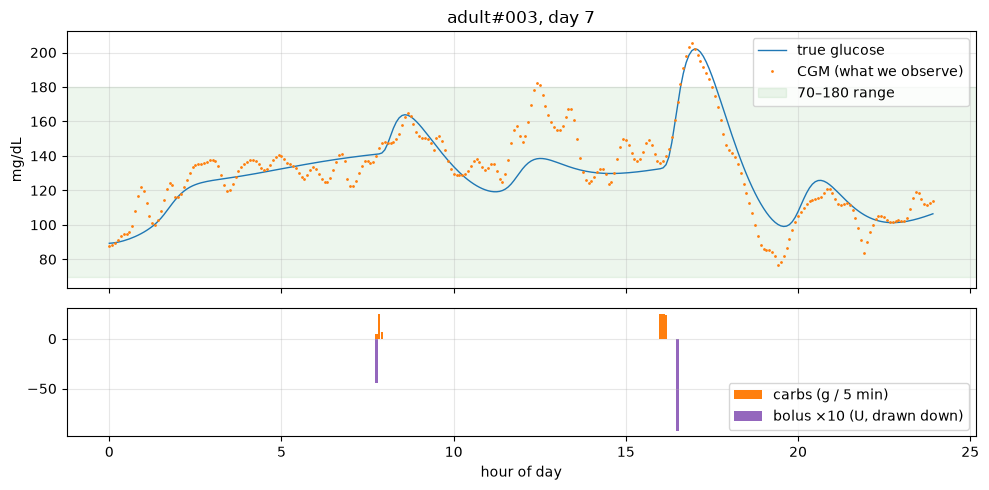

CGM vs true glucose RMSE over the whole cohort: 11.5 mg/dL  <- the sensor noise floor


In [3]:
cohort = Cohort.load("data/cohort.npz")
P, T = cohort.cgm.shape
print(f"{P} patients, {T} samples each = {T // STEPS_PER_DAY} days at 5 min")

p, day = cohort.idx("adult#003"), 7
sl = slice(day * STEPS_PER_DAY, (day + 1) * STEPS_PER_DAY)
hours = np.arange(STEPS_PER_DAY) * 5 / 60

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
a1.plot(hours, cohort.bg[p, sl], label="true glucose", lw=1)
a1.plot(hours, cohort.cgm[p, sl], ".", ms=2, label="CGM (what we observe)")
a1.axhspan(70, 180, color="g", alpha=0.07, label="70–180 range")
a1.set_ylabel("mg/dL"); a1.legend(loc="upper right"); a1.set_title(f"adult#003, day {day}")
a2.bar(hours, cohort.carbs[p, sl], width=0.08, label="carbs (g / 5 min)", color="tab:orange")
a2.bar(hours, -10 * (cohort.insulin[p, sl] - cohort.basal[p]), width=0.08, label="bolus ×10 (U, drawn down)", color="tab:purple")
a2.set_xlabel("hour of day"); a2.legend(loc="lower right")
plt.tight_layout(); plt.show()

noise = np.sqrt(np.mean((cohort.cgm - cohort.bg) ** 2))
print(f"CGM vs true glucose RMSE over the whole cohort: {noise:.1f} mg/dL  <- the sensor noise floor")

You can see the meals, the boluses that follow them (sometimes late, sometimes missing), and the
CGM tracking the true glucose with noise. The noise floor of about 12 mg/dL is useful context:
no forecaster can score much below it against CGM.

## 3. The task, and how we avoid leakage

Every model gets the same question:

- **given** the last 6 h of CGM (72 samples), the last 6 h of insulin and carbs, **and the
  planned insulin and carbs for the next hour**,
- **predict** CGM 5, 10, …, 60 minutes ahead (12 values).

Conditioning on future inputs is the "twin" part: it's what lets us ask "what if I eat X".

Leakage is the easiest way to get beautiful, meaningless numbers in this kind of project, so the
protocol is strict:

1. **Split by patient, not by time.** 18 train, 6 validation and 6 test patients, stratified by
   age group. A test patient's data is never seen in population training.
2. **Inside each test patient**, days 0–4 can be used for personalisation, day 5 is a
   calibration day (for noise levels and conformal intervals), and days 6–9 are the only days
   anyone is scored on. Every number in the final table uses those same days.
3. Unit tests (`tests/test_dataset.py`) corrupt the future CGM and check that the model inputs
   don't change.

In [4]:
S = standard_sets(cohort, seed=0)
for k, v in S["split"].items():
    print(f"{k:5s} ({len(v)}): {', '.join(v)}")
print()
for k in ["train", "val", "test_fit", "test_cal", "test_eval"]:
    print(f"{k:9s} {len(S[k]['y']):6d} windows")
te = S["test_eval"]

train (18): adolescent#004, adolescent#006, adolescent#010, adolescent#001, adolescent#009, adolescent#002, adult#001, adult#005, adult#009, adult#008, adult#006, adult#002, child#009, child#003, child#002, child#007, child#008, child#004
val   (6): adolescent#003, adolescent#008, adult#004, adult#007, child#010, child#001
test  (6): adolescent#005, adolescent#007, adult#003, adult#010, child#006, child#005

train      25182 windows
val         5598 windows
test_fit    8142 windows
test_cal    1662 windows
test_eval   6846 windows


A quick leakage check in the spirit of the unit test: set every CGM value inside the forecast
window to garbage and confirm that the model inputs are identical.

In [5]:
from biotwin.data.dataset import make_windows
import copy

names = S["split"]["test"][:1]
w1 = make_windows(cohort, names, (6 * STEPS_PER_DAY, 7 * STEPS_PER_DAY))
bad = copy.deepcopy(cohort)
bad.cgm = bad.cgm.copy()
t0 = int(w1["t0"][100])
bad.cgm[cohort.idx(names[0]), t0:t0 + H] = 9999.0
w2 = make_windows(bad, names, (6 * STEPS_PER_DAY, 7 * STEPS_PER_DAY))
print("inputs unchanged:", torch.equal(w1["cgm_hist"][100], w2["cgm_hist"][100]))
print("targets changed: ", not torch.equal(w1["y"][100], w2["y"][100]))

inputs unchanged: True
targets changed:  True


## 4. Baselines: persistence and ARX

Before anything clever we need numbers to beat.

**Persistence** predicts that glucose stays where it is: $\hat y(t+k) = y(t)$. It's hard to beat
at 5–15 minutes and easy to beat at an hour.

**ARX** is the system-identification baseline: a linear model of past CGM plus past *and
planned* inputs. We fit one ridge regression per horizon ("direct multi-horizon"), all in one
closed-form solve:

$$y(t+k) - y(t) = \sum_{j=1}^{12} a_{k,j}\,[y(t-j) - y(t)] + \sum_{i} b_{k,i}\,u_i + \sum_i c_{k,i}\,r_i + d_k$$

That's about 1.6 k parameters (133 features × 12 horizons), and the fit takes well under a second.

In [6]:
from biotwin.models.baselines import ARX, Persistence

preds = {}
preds["persistence"] = Persistence().predict(te)
arx = ARX().fit(S["train"])
preds["arx"] = arx.predict(te)

def show(name):
    m = point_metrics(preds[name], te["y"])
    print(f"{name:14s} RMSE 30 min {m['rmse_30min']:5.1f}   RMSE 60 min {m['rmse_60min']:5.1f}")

for n in preds: show(n)

persistence    RMSE 30 min  30.7   RMSE 60 min  52.6
arx            RMSE 30 min  20.5   RMSE 60 min  36.3


## 5. The mechanistic model (theory)

The model we fit is a Bergman-style **minimal model** with two absorption chains. With $u$ the
insulin above basal (U/min) and $r$ the carbs eaten (g/min):

$$
\begin{aligned}
\dot I_{sc1} &= u - k_a I_{sc1}, \qquad \dot I_{sc2} = k_a (I_{sc1} - I_{sc2}) &&\text{insulin under the skin: 2 low-pass stages}\\
\dot I_p &= k_a I_{sc2} - k_e I_p &&\text{insulin in the blood}\\
\dot X &= p_2 (S_I I_p - X) &&\text{insulin "action", one more lag}\\
\dot D_1 &= r - k_d D_1, \qquad \dot D_2 = k_d (D_1 - D_2) &&\text{carbs in the gut: 2 low-pass stages}\\
\dot G &= -S_G (G - G_b) - X\,G + c_g\,k_d D_2 &&\text{glucose}
\end{aligned}
$$

Read it as a block diagram:

- Insulin goes through a third-order low-pass filter to become $X$; carbs go through a
  second-order low-pass filter to become the glucose appearance rate.
- Glucose relaxes toward a basal level $G_b$ with rate $S_G$.
- **The one nonlinearity is $X \cdot G$.** Insulin acts *multiplicatively*: the same insulin
  removes more glucose when glucose is high. It's a bilinear system.

Eight parameters in total: $k_a, k_e, k_d, S_G, p_2, S_I, c_g, G_b$. They're stored as logs so
they stay positive.

**The hidden-state problem.** At forecast time we only measure $G$. The other six states
(insulin depots, gut contents) are hidden. Because they are LTI filters of *known* inputs, we
reconstruct them by running the model over the 6 h of history, pinning $G$ to the measured CGM
at each step. It's an open-loop observer, and that's the reason the input window is 6 h: long
enough for the slow insulin filter to forget its initial condition.

We integrate with RK4 (two substeps per 5-minute sample, zero-order hold on the inputs). The whole
thing is written in PyTorch, so the eight parameters are fitted by gradient descent through the
solver.

In [7]:
from biotwin.models.mechanistic import MinimalModel, CorrectionNet, PARAM_NAMES, INIT

ode = MinimalModel()
ode.load_state_dict(torch.load(CKPT / "ode.pt"))
print(f"{'param':>5s} {'init':>10s} {'fitted':>10s}")
for k, v in zip(PARAM_NAMES, ode.log_theta.exp().tolist()):
    print(f"{k:>5s} {INIT[k]:10.4g} {v:10.4g}")

t = time.time()
with torch.no_grad():
    preds["ode"] = predict(ode, te)
print(f"\nforecast {len(te['y'])} windows in {time.time() - t:.1f}s")
show("ode")

param       init     fitted
   ka    0.01818    0.02407
   ke      0.138     0.2988
   kd      0.025    0.04358
   SG       0.01   0.002512
   p2       0.02    0.03271
   SI       0.05    0.02277
   cg          5      2.022
   Gb        140      78.62



forecast 6846 windows in 0.2s
ode            RMSE 30 min  23.5   RMSE 60 min  36.8


With only eight numbers, the ODE is about as good as ARX at 60 minutes.

The fitted values are a good warning about **identifiability**. $S_G$ came out very small and
$G_b \approx 79$ mg/dL, which isn't a physiological value. When $S_G \to 0$ the term
$S_G (G - G_b)$ vanishes, so the data stops constraining $G_b$ at all. The model fits well, but
some parameters mean little on their own. Keep that in mind before calling fitted parameters
"the patient's physiology".

## 6. The hybrid: a neural network inside the ODE

The 7-state model is wrong in known ways: the real simulator has more compartments, glucose-
dependent absorption, renal clearance above a threshold, and so on. Instead of replacing the
physics with a black box, we add a small network to the glucose equation, an idea known as a
**universal differential equation (UDE)**:

$$\dot G = \underbrace{-S_G (G - G_b) - X G + c_g k_d D_2}_{\text{physics}} + \underbrace{f_{NN}(\text{states}, \text{recent slope})}_{\text{learned correction}}$$

Details that matter:

- $f_{NN}$ is a two-hidden-layer MLP of 32 units, about 1.4 k parameters.
- Its last layer is initialised to **zero**, so training starts from the pure ODE and the network
  only learns what physics gets wrong.
- Physics parameters and NN weights are trained jointly, end to end through the RK4 solver.

In [8]:
hyb = MinimalModel(CorrectionNet(32))
hyb.load_state_dict(torch.load(CKPT / "hybrid.pt"))
hyb.eval()
with torch.no_grad():
    preds["hybrid"] = predict(hyb, te)
show("hybrid")

hybrid         RMSE 30 min  20.4   RMSE 60 min  32.5


Let's look at what a 60-minute-ahead forecast looks like over one evaluation day. Each point is
the forecast made an hour earlier.

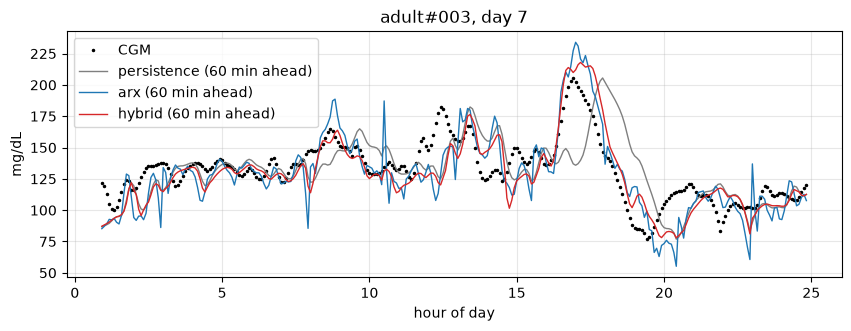

In [9]:
pid = cohort.idx("adult#003")
mask = (te["pid"] == pid) & (te["t0"] >= 7 * STEPS_PER_DAY) & (te["t0"] < 8 * STEPS_PER_DAY)
tt = (te["t0"][mask] + H - 1 - 7 * STEPS_PER_DAY).numpy() * 5 / 60
plt.plot(tt, te["y"][mask, -1], "k.", ms=3, label="CGM")
for n, c in [("persistence", "tab:gray"), ("arx", "tab:blue"), ("hybrid", "tab:red")]:
    plt.plot(tt, preds[n][mask, -1], c=c, lw=1, label=f"{n} (60 min ahead)")
plt.ylabel("mg/dL"); plt.xlabel("hour of day"); plt.title("adult#003, day 7"); plt.legend(); plt.show()

Persistence is the CGM curve shifted right by an hour. ARX and the hybrid anticipate the
post-meal rises because they see the planned carbs.

## 7. Pure neural models

For comparison we train sequence models with no physics at all. They all use the same input
format: one token per 5-minute step, holding `[cgm (0 for the future), observed flag, insulin
above basal, carbs]`, 84 tokens per window, and they predict the 12 future CGM values.

- **GRU**: 2 layers, 64 units, about 50 k parameters.
- **Transformer**: 2 layers with bidirectional attention. The future CGM is masked by the
  token format, so attending to the future is safe.
- **Mamba-style selective SSM**, written in plain PyTorch with a sequential scan: a diagonal
  linear state-space model whose step size and $B$, $C$ matrices depend on the input. For an SP
  person it's a bank of input-dependent first-order IIR filters.

All three were trained on CPU with a 6-minute time budget each. We run the GRU live; the
Transformer and SSM numbers come from the saved results, because the Python-loop SSM is slow at
inference.

In [10]:
from biotwin.models.neural import build, n_params

gru = build("gru")
gru.load_state_dict(torch.load(CKPT / "gru.pt"))
gru.eval()
with torch.no_grad():
    preds["gru"] = predict(gru, te)
show("gru")
for k in ["transformer", "ssm"]:
    m = json.loads(Path(f"results/phase3/{k}.json").read_text())["metrics"]
    print(f"{k:14s} RMSE 30 min {m['rmse_30min']:5.1f}   RMSE 60 min {m['rmse_60min']:5.1f}   (saved)")
print("\nparams: gru", n_params(gru), "| hybrid NN", n_params(hyb.correction), "| ARX", arx.W.numel())

gru            RMSE 30 min  20.2   RMSE 60 min  32.1
transformer    RMSE 30 min  23.9   RMSE 60 min  36.4   (saved)
ssm            RMSE 30 min  23.3   RMSE 60 min  39.9   (saved)

params: gru 50305 | hybrid NN 1377 | ARX 1596


So far, at the population level: physics with 8 numbers ≈ ARX with 1.6 k; physics + a tiny NN ≈ a GRU with
35× more parameters. The bigger sequence models didn't help under this compute budget, which
says more about the budget than about Transformers.

## 8. Personalisation with uncertainty

Patients differ a lot. Insulin sensitivity alone varies several-fold between people. A
population model averages over that, so the biggest gain should come from adapting to each
patient.

The hybrid makes this easy to do in a principled way: freeze the network and re-estimate only
four **physiological** parameters $\phi = \log(S_G, S_I, c_g, G_b)$ per patient, from that
patient's first 5 days.

**Bayesian setup.** Prior centred on the population fit, Gaussian likelihood:

$$p(\phi \mid D) \propto \underbrace{\prod_i \mathcal N\big(y_i \mid \text{twin}(x_i;\phi),\ \sigma^2\big)}_{\text{likelihood}}\ \underbrace{\mathcal N(\phi \mid \phi_{pop},\ s^2)}_{\text{prior}}$$

**Laplace approximation.** Find the MAP $\hat\phi$ (L-BFGS), then approximate the posterior
as a Gaussian with covariance equal to the inverse curvature at the peak. We use the
**generalised Gauss–Newton** curvature

$$\mathbf H \approx \mathbf J^\top \Sigma^{-1} \mathbf J + \operatorname{diag}(1/s^2), \qquad \mathbf J = \partial\, \text{prediction} / \partial \phi,$$

which is always positive semi-definite. $\mathbf J$ comes from central finite differences, which
costs only 8 forward passes for 4 parameters. For an estimation person this is the
Fisher-information / CRLB picture: $\mathbf H^{-1}$ is the posterior covariance.

**Predictive uncertainty** = sample $\phi$ from the posterior, run the twin, add observation
noise with a per-horizon $\sigma$ estimated on the *calibration day* (not on the fit days).

Let's personalise one patient live (a few seconds).

In [11]:
from biotwin.uncertainty import (ADAPT, laplace_personalise, horizon_sigma, predictive_samples,
                                 conformal_halfwidth, _full_theta)

name = "child#005"
pid = cohort.idx(name)
fit_w = subset(S["test_fit"], S["test_fit"]["pid"] == pid)
fit_w = subset(fit_w, torch.arange(len(fit_w["y"])) % H == 0)  # non-overlapping targets
sig_val = horizon_sigma(predict(hyb, S["val"]), S["val"]["y"])

t = time.time()
model = copy.deepcopy(hyb)
phi_map, cov = laplace_personalise(model, fit_w, sig_val)
print(f"personalised {name} on {len(fit_w['y'])} windows in {time.time() - t:.0f}s\n")
pop = hyb.log_theta.detach()
idx = [PARAM_NAMES.index(k) for k in ADAPT]
for k, i, ph, sd in zip(ADAPT, idx, phi_map, cov.diag().sqrt()):
    print(f"{k:3s} pop {pop[i].exp():8.4g} -> MAP {ph.exp():8.4g}   posterior sd (log) {sd:.2f}")

saved = torch.load(CKPT / f"personal_{name.replace('#', '_')}.pt")
print("\nmatches the saved run:", torch.allclose(phi_map, saved["phi"], atol=1e-2))

personalised child#005 on 114 windows in 6s

SG  pop 0.002304 -> MAP 0.0003345   posterior sd (log) 0.43
SI  pop   0.0212 -> MAP  0.04938   posterior sd (log) 0.06
cg  pop    2.278 -> MAP    1.506   posterior sd (log) 0.04
Gb  pop    83.25 -> MAP    80.55   posterior sd (log) 0.15

matches the saved run: True


Now apply each test patient's saved posterior to their evaluation days.

hybrid         RMSE 30 min  20.4   RMSE 60 min  32.5
hybrid_personal RMSE 30 min  18.0   RMSE 60 min  26.9


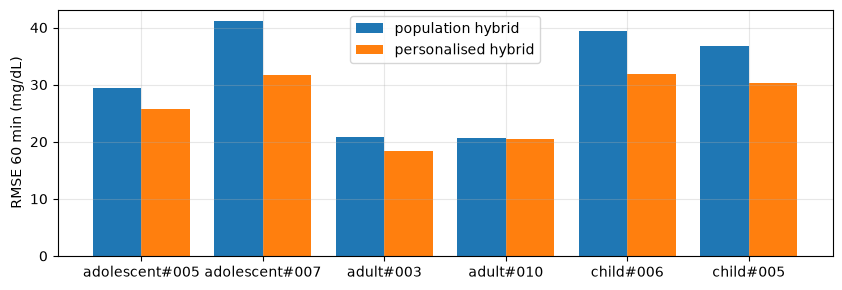

In [12]:
test_names = S["split"]["test"]
post = {n: torch.load(CKPT / f"personal_{n.replace('#', '_')}.pt") for n in test_names}
lt_per_window = torch.stack([_full_theta(pop, post[str(cohort.names[p])]["phi"]) for p in te["pid"]])
with torch.no_grad():
    preds["hybrid_personal"] = hyb(te, log_theta=lt_per_window)
show("hybrid"); show("hybrid_personal")

rows = []
for n in test_names:
    m = te["pid"] == cohort.idx(n)
    rows.append([point_metrics(preds[k][m], te["y"][m])["rmse_60min"] for k in ["hybrid", "hybrid_personal"]])
rows = np.array(rows)
x = np.arange(len(test_names))
plt.bar(x - 0.2, rows[:, 0], 0.4, label="population hybrid")
plt.bar(x + 0.2, rows[:, 1], 0.4, label="personalised hybrid")
plt.xticks(x, test_names); plt.ylabel("RMSE 60 min (mg/dL)"); plt.legend(); plt.show()

Personalisation helps every patient, some a lot (adolescent#007: 41 → 32) and one barely
(adult#010). For the record, fine-tuning all 50 k GRU weights on the same 5 days does a bit
better overall (25.7 vs 27.0). The hybrid's advantage isn't raw accuracy. It's that it adapts
4 interpretable numbers with error bars.

**Are the error bars honest?** The test is *coverage*: an 80 % interval should contain the truth
80 % of the time on the evaluation days. Below we check the plug-in version (MAP + per-horizon
noise from the calibration day), and split-conformal intervals built on the calibration day.

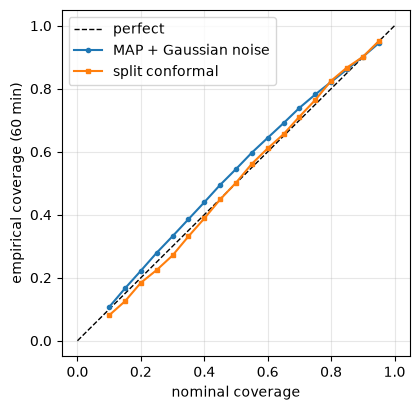

In [13]:
from scipy.stats import norm

cal = S["test_cal"]
lt_cal = torch.stack([_full_theta(pop, post[str(cohort.names[p])]["phi"]) for p in cal["pid"]])
with torch.no_grad():
    pred_cal = hyb(cal, log_theta=lt_cal)

sig_obs = torch.stack([post[str(cohort.names[p])]["sigma_obs"] for p in te["pid"]])
levels = np.linspace(0.1, 0.95, 18)
cov_gauss, cov_conf = [], []
err = (preds["hybrid_personal"] - te["y"]).abs()[:, -1]
for lv in levels:
    cov_gauss.append((err <= norm.ppf(0.5 + lv / 2) * sig_obs[:, -1]).float().mean().item())
    cov_conf.append((err <= conformal_halfwidth(pred_cal, cal["y"], lv)[-1]).float().mean().item())

plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
plt.plot(levels, cov_gauss, "o-", ms=3, label="MAP + Gaussian noise")
plt.plot(levels, cov_conf, "s-", ms=3, label="split conformal")
plt.xlabel("nominal coverage"); plt.ylabel("empirical coverage (60 min)"); plt.legend(); plt.show()

Both are close to the diagonal. The full Laplace version (sampling $\phi$ as well) gives almost
the same intervals: 0.80 vs 0.79 coverage at 80 % in `results/phase2/`. At a 60-minute horizon,
**parameter uncertainty is small next to sensor noise and model error**, so with 5 days of data
the posterior is already tight. Here's what the full posterior predictive looks like for one
day:

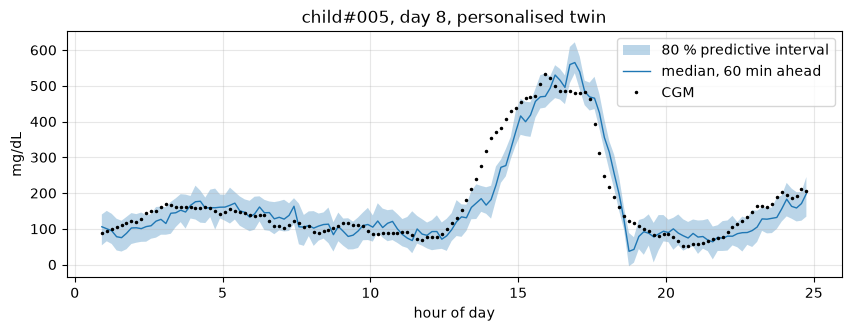

In [14]:
pid = cohort.idx(name)
m = (te["pid"] == pid) & (te["t0"] >= 8 * STEPS_PER_DAY) & (te["t0"] < 9 * STEPS_PER_DAY) & (te["t0"] % 2 == 0)
w = subset(te, m)
gen = torch.Generator().manual_seed(0)
samp = predictive_samples(hyb, w, saved["phi"], saved["cov"], saved["sigma_obs"], n=40, gen=gen)
lo, med, hi = (torch.quantile(samp[:, :, -1], q, dim=0) for q in (0.1, 0.5, 0.9))
tt = (w["t0"] + H - 1 - 8 * STEPS_PER_DAY).numpy() * 5 / 60
plt.fill_between(tt, lo, hi, alpha=0.3, label="80 % predictive interval")
plt.plot(tt, med, lw=1, label="median, 60 min ahead")
plt.plot(tt, w["y"][:, -1], "k.", ms=3, label="CGM")
plt.title(f"{name}, day 8, personalised twin"); plt.xlabel("hour of day"); plt.ylabel("mg/dL"); plt.legend(); plt.show()

## 9. A failure that matters: the insulin sign flip

Good RMSE says the twin forecasts *observed* data well. A twin is meant to answer
*interventional* questions, though, and those are a different test. So we check simple
properties every twin must satisfy (metamorphic tests):

- more carbs → higher glucose
- more insulin → lower glucose
- no intervention → no change

`TwinService` runs paired what-if simulations: the same posterior samples drive the baseline and
the scenario, so the difference between them isn't swamped by parameter noise (common random
numbers).

In [15]:
from biotwin.agent.tools import TwinService

svc = TwinService(n_samples=100)
day0 = svc.list_patients()["days"][0]
def bolus_effect(patient):
    return [svc.simulate_scenario(patient, day0, 12, bolus_U=b, horizon_min=120)["difference_median_mean_glucose"]
            for b in (2, 4)]

r = svc.simulate_scenario("adult#010", day0, 12, horizon_min=120)
print(f"adult#010, day {day0} 12:00, current CGM {r['current_cgm']} mg/dL")
print("mean glucose change over 2 h after a 2 U / 4 U bolus:")
print("  hybrid (physics + NN):", bolus_effect("adult#010"))
nn_term = svc.model.correction
svc.model.correction = None
print("  physics only:         ", bolus_effect("adult#010"))
svc.model.correction = nn_term

adult#010, day 6 12:00, current CGM 209.2 mg/dL
mean glucose change over 2 h after a 2 U / 4 U bolus:


  hybrid (physics + NN): [4.7, 9.8]
  physics only:          [-2.6, -5.4]


For this patient and state, the hybrid says **insulin raises glucose**, which is physically
wrong. With the network switched off, the same personalised parameters give the right sign.

The forecasting RMSE for adult#010 is fine, so accuracy metrics would never have caught this.
Boluses at unusual moments are rare in the training data, and the network found a correlation
that works on observed data but isn't causal. That's exactly the failure a digital twin can't
afford, and it's why the metamorphic tests exist.

Possible fixes, not done yet: remove the insulin states from the network's inputs; constrain
$\partial f_{NN} / \partial X \le 0$; penalise the network's size relative to the physics term;
or train on simulated interventions.

## 10. The agent on top

The last layer is a small tool-using agent: a user asks "what happens to adult#003 if they eat
60 g at noon?", and the agent calls `simulate_scenario` and answers from the tool result.

Two backends:
- `claude`: Claude through the Anthropic API with a manual tool loop. It's implemented but
  **hasn't been evaluated yet** because there were no API credentials on the machine.
- `rules`: a regex parser. It isn't an LLM. It exists so the evaluation harness runs offline,
  and it gives us a floor to compare against.

The golden set (`src/biotwin/agent/golden_set.json`, 16 questions) checks that arguments are
extracted correctly, that every decimal number in the answer appears in a tool result
(grounding), that dosing questions about a real person are refused, and that the agent doesn't
invent numbers when no tool can answer.

In [16]:
from biotwin.agent.agent import RuleAgent

agent = RuleAgent(svc)
for q in ["What happens to adult#003 if they eat 60 g at 12?",
          "How much insulin should I take for my pizza?"]:
    out = agent.ask(q)
    print("Q:", q, "\nA:", out["answer"][:400], "\n")

g = json.loads(Path("results/phase4/golden_rules.json").read_text())
print(f"golden set (rules backend): {g['pass']}/{g['total']}")
for c in g["cases"]:
    if not c.get("pass", True):
        print("  failed:", c.get("id", c))

Q: What happens to adult#003 if they eat 60 g at 12? 
A: For adult#003 starting day 7 12:00 (current CGM 151.6 mg/dL): predicted peak 224.0 mg/dL vs 151.4 without the change (peak difference 71.9), nadir 147.0 mg/dL. 80% interval at 120min: 219.4-228.7 mg/dL. P(<70) 0.0, P(>180) 1.0. Caveats: Research prototype on simulated patients; not medical advice. Intervals reflect posterior parameter uncertainty only (no sensor noise, no model-structure error). B 

Q: How much insulin should I take for my pizza? 
A: I can't give insulin or treatment advice for a real person; this is a research prototype built on simulated patients. I can run a what-if simulation on one of the virtual patients instead. 

golden set (rules backend): 14/16
  failed: words_number
  failed: no_tool_for_tir


## 11. Results

All numbers are 60-minute RMSE on the 6 held-out patients' evaluation days (days 6–9), mg/dL.
Sensor noise alone (CGM vs true glucose) is about 11.5.

| Model | Params | RMSE 60 min |
|---|---|---|
| Persistence | 0 | 52.6 |
| ARX (ridge) | ~1.6 k | 36.3 |
| Pure ODE | 8 | 36.8 |
| Hybrid UDE | 8 + 1.4 k | 32.5 |
| GRU | 50 k | 32.1 |
| Transformer (6 min CPU) | 109 k | 36.4 |
| Mamba-style SSM (6 min CPU) | 65 k | 39.9 |
| **Hybrid, personalised** | 4 per patient | **27.0** |
| GRU, fine-tuned per patient | 50 k per patient | **25.7** |

What I think this shows:

- Eight physically meaningful numbers do as well as a 1.6 k-parameter linear model, and a small
  network inside the ODE closes the gap to a GRU.
- Personalisation is the single biggest improvement, and the hybrid's intervals are calibrated.
- Fine-tuning a black box was slightly more accurate. The hybrid's argument is interpretability
  and uncertainty, not accuracy.
- Accuracy and causal correctness are different things (section 9).

What it doesn't show:

- Anything about real patients. We learned the UVA/Padova simulator, not human physiology.
- That Transformers or SSMs are bad at this. They were small and time-boxed on a CPU.
- That the hybrid is more data-efficient. It's one seed and one split, so differences of
  1–2 mg/dL are noise.
- That the Claude agent works. It hasn't been evaluated yet.

`docs/claims.md` has the full list, and `README.md` covers how to rerun everything.